# 이진 분류 실험 ② — 같은 쌍 반복 피처 추가 (pair history)
1단계 피처 사다리의 첫 칸. 01(기본 4 + port 2) 위에 **두 계좌 사이의 반복 거래** 피처 4개를 더한다. 모델은 GINe 고정, 나머지 설정은 01 과 동일.

| 피처 | 뜻 | 출처 |
|---|---|---|
| `pair_prior_count` | 이 거래 전에 같은 (src→dst) 로 보낸 횟수 (처음부터, 같은 분 제외) | v10 엣지 피처 |
| `pair_gap_minutes` | 직전 같은 쌍 거래까지의 분 (ln) | v10 |
| `pair_count_1h` | 최근 60분 안 같은 쌍 횟수 | v10 |
| `reverse_history_count` | 반대 방향 (dst→src) 누적 횟수 (전날까지) | v10 |

**가설**: 같은 상대에게 반복해서 보내거나(STACK, 반복 송금), 주고받는(BIPARTITE, 왕복) 패턴의 recall 이 오른다. FAN·CYCLE 은 거의 안 변해야 정상.

**누수 규칙**: 전부 거래 시각 기준 **과거**만 (v10 과 같이 같은 분은 제외). z-norm 은 학습 구간 통계. 공통 코드는 `bc_lib.py` (01 코드를 함수로 옮긴 것)

# 공통 부분 (작업 준비, 데이터 준비)

## 0. 작업 준비

In [1]:
import sys, json, time, gc
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

sys.path.append(str(Path.cwd()))
import bc_lib as B
L = B.L

In [2]:
# ---- 실험 설정 ------------------------------------------------------------
RUN_NAME = 'pair_history'         # results/<DATASET>/pair_history/
PREV_RUN = 'basic_features'       # 비교 기준 (01)
cfg = B.Config(dataset='HI-Large', smoke=False)
B.seed_all(cfg.seed)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUT_DIR = cfg.out_dir(RUN_NAME)

# 이번 단계 피처
STAGE_FEATURES = ['pair_prior_count', 'pair_gap_minutes', 'pair_count_1h', 'reverse_history_count']
STAGE_PATH = cfg.feat_dir / 'pair_history.parquet'
GNN_EDGE_FEATURES = B.BASIC_EDGE_FEATURES + B.PORT_FEATURES + STAGE_FEATURES     # FEAT16 열 순서. port 는 4,5 번
TREE_FEATURES = B.BASIC_EDGE_FEATURES + STAGE_FEATURES                           # 트리는 port 없이 (GFP "basic" + 이번 피처)
DEVICE, OUT_DIR, len(GNN_EDGE_FEATURES)

(device(type='cuda'),
 PosixPath('/workspace/money_laundry_ai_/code/binary_classification/results/HI-Large/pair_history'),
 10)

In [3]:
cfg

Config(dataset='HI-Large', smoke=False, val_neg_rate=0.02, scale_pos_weight=6, tree_rounds=500, tree_early_stop=20, num_neighbors=[100, 100], batch_size=2048, iter_per_epoch=256, epochs=400, eval_period=4, patience=8, class_weight=[1.0, 6.27], n_hidden=66, n_gnn_layers=2, lr=0.006, dropout=0.01, final_dropout=0.1, num_workers=0, seed=42)

## 1. 데이터 준비 — 거래 전체 + port

In [4]:
con = L.connect(threads=8, memory='12GB')
currency_codes, format_codes = B.code_tables(con, cfg)
PORTS_PATH = B.ensure_ports(con, cfg)               # 있으면 건너뜀
tx = B.load_tx(con, cfg)
tx = B.attach_parquet(tx, PORTS_PATH, B.PORT_FEATURES)
tx.shape

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

(179702079, 11)

In [5]:
tx.head()

,edge_id,src,dst,day,timestamp,amount_received,received_currency,payment_format,y,in_port,out_port
0,1,3,3,2022-08-01,0.0,19.180000,12,5,0,0,0
1,2,25,78803,2022-08-01,0.0,17955.109375,12,3,0,0,0
2,3,31,86028,2022-08-01,0.0,1199.829956,12,2,0,0,0
3,4,39,269980,2022-08-01,0.0,148565.453125,12,6,0,0,0
4,5,50,29866,2022-08-01,0.0,227247.421875,12,3,0,0,0


## 2. 이번 단계 피처 계산 — 같은 쌍 반복

- DuckDB 창 함수. v10 `02_build_features` 의 SQL 과 같은 정의 (`EXCLUDE='1 minute'`, `HOUR_WINDOW='60 minutes'`)
- `pair_prior`/`pair_hour`: 같은 (src, dst) 파티션에서 거래 시각 기준 **1분 전까지** 센다 (같은 분 거래는 제외 — 서비스와 동일)
- `reverse_n`: 전날까지의 (dst→src) 누적 횟수. 일 단위 상태 테이블에 ASOF 조인 (v10 과 동일)
- 결과는 `features_bc/pair_history.parquet` 로 저장 (edge_id 순). 한 번 만들면 재사용. pandas 를 거치지 않는다

In [6]:
if not STAGE_PATH.exists():
    t0 = time.time()
    con.execute(f"""
        CREATE OR REPLACE TABLE tx_min AS
        SELECT edge_id, src, dst, ts, day FROM read_parquet({L.q(cfg.tx_path)})""")
    # (a) 같은 쌍 시간 창 (v10 cell 11 의 pair 부분)
    con.execute("""
        CREATE OR REPLACE TABLE pair_win AS
        SELECT edge_id, ts,
               count(*) OVER (PARTITION BY src, dst ORDER BY ts RANGE BETWEEN UNBOUNDED PRECEDING AND INTERVAL '1 minute' PRECEDING) AS pair_prior,
               max(ts)  OVER (PARTITION BY src, dst ORDER BY ts RANGE BETWEEN UNBOUNDED PRECEDING AND INTERVAL '1 minute' PRECEDING) AS pair_last,
               count(*) OVER (PARTITION BY src, dst ORDER BY ts RANGE BETWEEN INTERVAL '60 minutes' PRECEDING AND INTERVAL '1 minute' PRECEDING) AS pair_hour
        FROM tx_min""")
    # (b) 반대 방향 누적 — 일 단위 상태 + ASOF (v10 cell 9)
    con.execute("""
        CREATE OR REPLACE TABLE pair_state AS
        SELECT src, dst, day, sum(n) OVER (PARTITION BY src, dst ORDER BY day ROWS UNBOUNDED PRECEDING) AS history_count
        FROM (SELECT src, dst, day, count(*) n FROM tx_min GROUP BY src, dst, day)""")
    con.execute("""
        CREATE OR REPLACE TABLE pairs AS
        SELECT t.src, t.dst, t.day, coalesce(r.history_count, 0) AS reverse_n
        FROM (SELECT DISTINCT src, dst, day FROM tx_min) t
        ASOF LEFT JOIN pair_state r ON t.src = r.dst AND t.dst = r.src AND t.day > r.day""")
    # (c) 변환 (ln) 후 저장
    con.execute(f"""
        COPY (
            SELECT t.edge_id,
                   ln(1 + w.pair_prior)::FLOAT                                                                       AS pair_prior_count,
                   (CASE WHEN w.pair_last IS NULL THEN 0 ELSE ln(2 + date_diff('minute', w.pair_last, t.ts)) END)::FLOAT AS pair_gap_minutes,
                   ln(1 + w.pair_hour)::FLOAT                                                                        AS pair_count_1h,
                   ln(1 + p.reverse_n)::FLOAT                                                                        AS reverse_history_count
            FROM tx_min t JOIN pair_win w USING (edge_id)
            JOIN pairs p ON t.src = p.src AND t.dst = p.dst AND t.day = p.day
            ORDER BY t.edge_id
        ) TO {L.q(STAGE_PATH)} (FORMAT PARQUET, COMPRESSION ZSTD)""")
    con.execute("DROP TABLE pair_win; DROP TABLE pair_state; DROP TABLE pairs; DROP TABLE tx_min")
    print(f'{STAGE_PATH.name} 생성 {time.time()-t0:.0f}s')
con.execute(f"SELECT count(*), {', '.join(f'avg({c}) AS avg_{c}' for c in STAGE_FEATURES)} FROM read_parquet({L.q(STAGE_PATH)})").df().T

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,0
count_star(),1.797021e+08
avg_pair_prior_count,3.745342e+00
avg_pair_gap_minutes,4.821949e+00
avg_pair_count_1h,3.787510e-01
avg_reverse_history_count,1.236571e-01


In [7]:
# 창 동작 확인 — 거래 8건에 가장 가까운 쌍 하나를 골라 타임라인으로 (prior 가 1씩 늘고, 같은 분은 안 세는지)
# 주의: 1.8억 건끼리 조인하면 메모리 초과 → 그 쌍의 edge_id 몇 개만 골라 피처 parquet 에서 읽는다
pair = con.execute(f"SELECT src, dst FROM read_parquet({L.q(cfg.tx_path)}) GROUP BY src, dst ORDER BY abs(count(*) - 8), src LIMIT 1").fetchone()
ids = con.execute(f"SELECT edge_id, ts FROM read_parquet({L.q(cfg.tx_path)}) WHERE src = {pair[0]} AND dst = {pair[1]} ORDER BY ts").df()
feat = con.execute(f"SELECT * FROM read_parquet({L.q(STAGE_PATH)}) WHERE edge_id IN ({', '.join(map(str, ids.edge_id))})").df()
ids.merge(feat, on='edge_id').sort_values('ts')

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,edge_id,ts,pair_prior_count,pair_gap_minutes,pair_count_1h,reverse_history_count
0,43686,2022-08-01 00:01:00,0.000000,0.000000,0.000000,0.0
1,261708,2022-08-01 00:06:00,0.693147,1.945910,0.693147,0.0
2,56731886,2022-08-31 00:19:00,1.098612,10.673943,0.000000,0.0
3,57467372,2022-08-31 00:28:00,1.386294,2.397895,0.693147,0.0
4,110308037,2022-09-30 00:01:00,1.609438,10.673017,0.000000,0.0
5,111625969,2022-09-30 00:17:00,1.791759,2.890372,0.693147,0.0
6,166339798,2022-10-30 07:30:00,1.945910,10.683615,0.000000,0.0
7,166348467,2022-10-30 07:34:00,2.079442,1.791759,0.693147,0.0


In [8]:
tx = B.attach_parquet(tx, STAGE_PATH, STAGE_FEATURES)
tx[STAGE_FEATURES].describe().T

,count,mean,std,min,25%,50%,75%,max
pair_prior_count,179702079.0,3.745342,1.499816,0.0,2.944439,4.219508,4.859812,6.536692
pair_gap_minutes,179702079.0,4.821949,3.047155,0.0,2.079442,3.332205,7.430707,12.220321
pair_count_1h,179702079.0,0.378751,0.440044,0.0,0.000000,0.000000,0.693147,2.302585
reverse_history_count,179702079.0,0.123657,0.628591,0.0,0.000000,0.000000,0.000000,6.532334


In [9]:
# 라벨별 평균 — 세탁 거래에서 값이 다른가 (피처가 신호를 갖는지 미리 확인). pandas groupby 는 열 단위라 가볍다
tx.groupby('y')[STAGE_FEATURES].mean().T.rename(columns={0: 'normal', 1: 'laundering'})

y,normal,laundering
pair_prior_count,3.749042,0.801016
pair_gap_minutes,4.824810,2.545596
pair_count_1h,0.379175,0.041125
reverse_history_count,0.123430,0.304658


## 3. z-norm (학습 구간 통계) + 표본

In [10]:
in_train = B.window_mask(tx, cfg.train_window)
feat_z, znorm_table = B.znorm_features(tx, GNN_EDGE_FEATURES, in_train)     # tx 에서 피처 열은 떨어짐
znorm_table

,feature,mean(train),std(train)
0,timestamp,3.036519e+06,1.403026e+06
1,amount_received,5.573174e+06,1.804616e+09
2,received_currency,8.450158e+00,4.231340e+00
3,payment_format,2.946519e+00,1.430707e+00
4,in_port,1.691504e+00,2.026216e+01
5,out_port,1.258211e+03,5.523149e+03
6,pair_prior_count,3.619840e+00,1.249556e+00
7,pair_gap_minutes,4.934093e+00,3.020734e+00
8,pair_count_1h,3.836407e-01,4.402390e-01
9,reverse_history_count,1.201977e-01,5.942421e-01


In [11]:
print(f"데이터 기간 {tx['day'].min().date()} ~ {tx['day'].max().date()}")
for name, w in [('train', cfg.train_window), ('val', cfg.val_window), ('test', cfg.test_window)]:
    m = B.window_mask(tx, w); assert m.sum() > 0, f'{name} 구간 {w} 에 거래가 없음'
    print(f'{name:5s} {w}  거래 {m.sum():>12,}  세탁 {tx.loc[m, "y"].sum():>8,}  비율 {tx.loc[m, "y"].mean()*100:.3f}%')

데이터 기간 2022-08-01 ~ 2023-01-12
train 2022-08-08:2022-10-02  거래  102,336,629  세탁  110,671  비율 0.108%
val   2022-10-03:2022-10-16  거래   24,413,046  세탁   33,795  비율 0.138%
test  2022-10-17:2022-10-30  거래   26,808,230  세탁   34,460  비율 0.129%


In [12]:
val_df = B.val_sample(con, cfg.val_window, cfg.val_neg_rate)        # 검증: 가중 표본 (05 공유)
test_df = B.test_full(con, cfg.test_window)                         # 테스트: 구간 전체
in_degree = B.recipient_indegree(con, cfg)                           # 분석용
con.close()

all_edge_ids = tx['edge_id'].to_numpy()
val_idx = B.rows_of(all_edge_ids, val_df['edge_id'].to_numpy()); test_idx = B.rows_of(all_edge_ids, test_df['edge_id'].to_numpy())
assert (tx['y'].to_numpy()[val_idx] == val_df['y'].to_numpy()).all()
del all_edge_ids
val_df.shape, test_df.shape

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

((521382, 7), (26808230, 5))

# 트리 모델 (기본 4 + 이번 피처 4)

## 4. LightGBM / XGBoost

In [13]:
results = {}
tree_cols = [GNN_EDGE_FEATURES.index(c) for c in TREE_FEATURES]
train_mask = in_train
X_train = feat_z[train_mask][:, tree_cols]; y_train = tx['y'].to_numpy()[train_mask]
X_val, y_val, w_val = feat_z[val_idx][:, tree_cols], val_df['y'].to_numpy(), val_df['w'].to_numpy()
X_test = feat_z[test_idx][:, tree_cols]
if cfg.smoke:
    keep = np.random.default_rng(cfg.seed).choice(len(X_train), min(len(X_train), 200_000), replace=False)
    X_train, y_train = X_train[keep], y_train[keep]
X_train.shape, X_test.shape

((102336629, 8), (26808230, 8))

In [14]:
results['gine'] = json.load(open(OUT_DIR / 'results.json'))['results']['gine']

In [45]:
lgb_model, xgb_model = B.train_trees(X_train, y_train, X_val, y_val, w_val, X_test, val_df, test_df, cfg, results)
pd.DataFrame({'feature': TREE_FEATURES, 'lightgbm_gain': lgb_model.booster_.feature_importance('gain'),
              'xgboost_gain': [xgb_model.get_booster().get_score(importance_type='gain').get(f'f{i}', 0.0) for i in range(len(TREE_FEATURES))]})

NameError: name 'X_train' is not defined

In [16]:
# 트리 테스트 점수도 저장 (분석용)
for name, model in [('lightgbm', lgb_model), ('xgboost', xgb_model)]:
    pd.DataFrame(dict(edge_id=test_df.edge_id, y=test_df.y, score=model.predict_proba(X_test)[:, 1])).to_parquet(OUT_DIR / f'{name}_test_scores.parquet', index=False)
del X_train, y_train, X_test; gc.collect()
pd.DataFrame({k: v['val'] for k, v in results.items()}).T.round(4)

,AP,F1,F1_at_0.5,precision,recall,threshold,recall_at_1pct,unmatched_recall_at_1pct,ECE
gine,0.5140,0.5605,0.4714,0.6867,0.4735,0.8617,0.7562,0.4403,0.0034
lightgbm,0.3117,0.4681,0.2041,0.6445,0.3675,1.0000,0.5741,0.3742,0.0060
xgboost,0.3543,0.4900,0.4881,0.6475,0.3941,0.5787,0.6222,0.3519,0.0048


# GNN (GINe, 01 과 같은 설정)

## 5. 그래프 — 한 번에 하나만 (bc_lib.GraphStore)

In [ ]:
store = B.GraphStore(tx, feat_z, cfg, train_rows=np.flatnonzero(train_mask), val_idx=val_idx, test_idx=test_idx,
                     port_cols=[GNN_EDGE_FEATURES.index('in_port'), GNN_EDGE_FEATURES.index('out_port')])
del tx, feat_z; B.trim('(tx, feat_z 삭제 후)')
store.edge_dim

In [ ]:
# 배치 하나 꺼내서 모양 확인 — 2048 target 이 서브그래프 하나를 공유, 엣지 피처 10열
batch = next(iter(store.use('train')))
print('노드', batch['node'].num_nodes, ' to 간선', batch[B.TO].num_edges, ' rev_to 간선', batch[B.REV].num_edges,
      ' target', batch[B.TO].edge_label_index.shape[1], ' 양성', int(batch[B.TO].edge_label.sum()),
      ' x 열', batch['node'].x.shape[1], ' edge_attr 열', batch[B.TO].edge_attr.shape[1], ' target_attr', tuple(batch.target_attr.shape))

In [ ]:
# 모델 모양 확인
model = B.make_gine(store.edge_dim, cfg, edge_updates=False).to(DEVICE)
logits, labels = B.forward_batch(model, batch, DEVICE)
print('파라미터', sum(p.numel() for p in model.parameters()), ' 로짓', tuple(logits.shape))
del model, batch

## 6. 학습 — GINe

In [ ]:
gine_model, gine_hist = B.train_gnn('gine', store, cfg, val_df, OUT_DIR, DEVICE, edge_updates=False, results=results)
results['gine']['val']

In [ ]:
# 학습 곡선
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
hv = gine_hist.dropna(subset=['AP']); ax[0].plot(hv['epoch'], hv['AP'], marker='o'); ax[1].plot(gine_hist['epoch'], gine_hist['train_loss'])
ax[0].set_title('val AP'); ax[1].set_title('train loss'); ax[0].set_xlabel('epoch'); ax[1].set_xlabel('epoch')
plt.tight_layout(); plt.savefig(OUT_DIR / 'curves.png', dpi=120); plt.show()

## 7. 테스트 — 구간 전체

In [ ]:
gine_score = B.test_gnn('gine', store, cfg, test_df, OUT_DIR, DEVICE, edge_updates=False, results=results)

# 결과

## 8. 패턴별 recall · degree 층화 — 01 과 비교

In [22]:
import importlib; importlib.reload(B)

<module 'bc_lib' from '/workspace/money_laundry_ai_/code/binary_classification/bc_lib.py'>

In [17]:
pattern_tables, degree_tables = [], []
for name in ['lightgbm', 'xgboost', 'gine']:
    sc = B.load_scores(OUT_DIR / f'{name}_test_scores.parquet')
    pattern_tables.append(B.pattern_recall(sc).assign(model=name))
    degree_tables.append(B.degree_stratified(sc, test_df['dst'].to_numpy(), in_degree).assign(model=name))
pattern_df, degree_df = pd.concat(pattern_tables), pd.concat(degree_tables)
pattern_df.to_csv(OUT_DIR / 'analysis_pattern.csv', encoding='utf-8-sig'); degree_df.to_csv(OUT_DIR / 'analysis_degree.csv', encoding='utf-8-sig')

In [23]:
# 패턴별 recall@1% — 이번 단계 GINe vs 01 GINe. 가설: STACK · BIPARTITE 가 오르고 FAN · CYCLE 은 비슷
prev = pd.read_csv(Path.cwd() / 'results' / cfg.dataset / PREV_RUN / 'analysis_pattern.csv', index_col=0)
cmp = pd.DataFrame({
    '01 gine_basic': prev[prev.model == 'gine_basic']['recall'],
    f'02 gine ({RUN_NAME})': pattern_df[pattern_df.model == 'gine']['recall'],
})
cmp['diff'] = cmp.iloc[:, 1] - cmp.iloc[:, 0]
cmp.loc[[p for p in B.PATTERN_ORDER + ['ALL'] if p in cmp.index]].round(4)

,01 gine_basic,02 gine (pair_history),diff
pattern_type,,,
FAN-OUT,0.9840,0.9855,0.0015
FAN-IN,0.9485,0.9282,-0.0203
GATHER-SCATTER,0.9609,0.9667,0.0058
SCATTER-GATHER,0.9758,0.9733,-0.0025
CYCLE,0.9665,0.9838,0.0173
RANDOM,0.9648,0.9865,0.0217
BIPARTITE,0.9525,0.9460,-0.0065
STACK,0.9630,0.9767,0.0137
UNMATCHED,0.4324,0.4692,0.0368


In [30]:
# 수신 계좌 degree 구간별 AP — 허브 구간이 달라졌나
prev_d = pd.read_csv(Path.cwd() / 'results' / cfg.dataset / PREV_RUN / 'analysis_degree.csv', index_col=0)
pd.DataFrame({
    '01 gine_basic AP': prev_d[prev_d.model == 'gine_basic']['AP'],
    '02 gine AP': degree_df[degree_df.model == 'gine']['AP'],
    '02 gine F1': degree_df[degree_df.model == 'gine']['F1'],
    'n_pos': degree_df[degree_df.model == 'gine']['n_pos'],
}).round(4)

,01 gine_basic AP,02 gine AP,02 gine F1,n_pos
bin,,,,
[1-4],0.7499,0.7277,0.7086,508
[5-9],0.7259,0.7419,0.7269,2604
[10-19],0.3906,0.4210,0.4800,4863
[20-49],0.2716,0.2763,0.3624,7132
[50-99],0.2883,0.3826,0.4573,2493
[100+],0.3878,0.5507,0.6175,16860


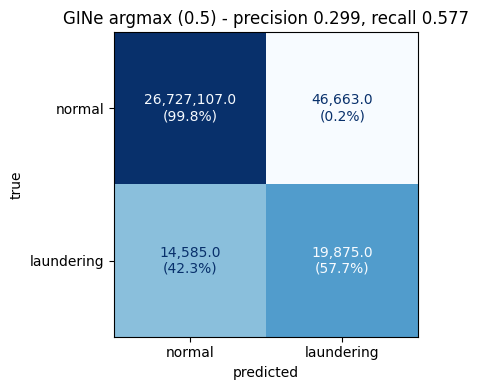

In [38]:
# 혼동행렬 그림 — 색은 행 정규화(laundering 행 = recall), 숫자는 건수
from sklearn.metrics import ConfusionMatrixDisplay
m = cb['matrix'].loc['argmax']
cm = np.array([[m.TN, m.FP], [m.FN, m.TP]])
fig, ax = plt.subplots(figsize=(4.5, 4))
disp = ConfusionMatrixDisplay(cm / cm.sum(axis=1, keepdims=True), display_labels=['normal', 'laundering'])
disp.plot(ax=ax, cmap='Blues', colorbar=False, values_format='.3f')
for i in range(2):
    for j in range(2):
        disp.text_[i, j].set_text(f'{cm[i, j]:,}\n({cm[i, j] / cm[i].sum():.1%})')
ax.set_xlabel('predicted'); ax.set_ylabel('true'); ax.set_title(f'GINe argmax (0.5) - precision {m.precision:.3f}, recall {m.recall:.3f}')
plt.tight_layout(); plt.savefig(OUT_DIR / 'confusion.png', dpi=120); plt.show()

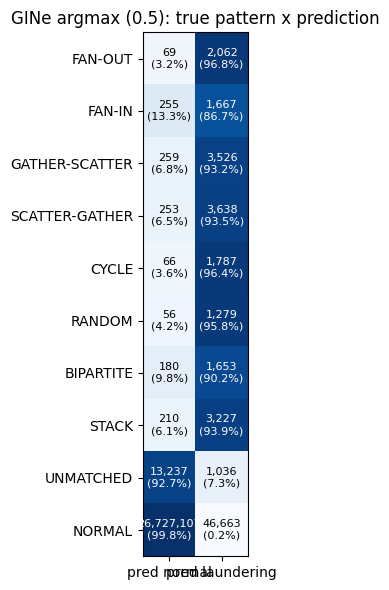

,pos_share,FN r@0.1%,FN% r@0.1%,FN r@0.5%,FN% r@0.5%,FN r@1%,FN% r@1%,FN r@2%,FN% r@2%,FN r@5%,FN% r@5%,FN argmax,FN% argmax
UNMATCHED,0.4142,14083,0.7893,11422,0.9309,7576,0.9237,4360,0.9782,2933,0.9796,13237,0.9076
SCATTER-GATHER,0.1129,636,0.0356,144,0.0117,104,0.0127,26,0.0058,20,0.0067,253,0.0173
GATHER-SCATTER,0.1098,627,0.0351,173,0.0141,126,0.0154,13,0.0029,5,0.0017,259,0.0178
STACK,0.0997,724,0.0406,118,0.0096,80,0.0098,16,0.0036,13,0.0043,210,0.0144
FAN-OUT,0.0618,190,0.0106,46,0.0037,31,0.0038,6,0.0013,5,0.0017,69,0.0047
FAN-IN,0.0558,594,0.0333,172,0.0140,138,0.0168,20,0.0045,6,0.0020,255,0.0175
CYCLE,0.0538,299,0.0168,41,0.0033,30,0.0037,6,0.0013,4,0.0013,66,0.0045
BIPARTITE,0.0532,450,0.0252,125,0.0102,99,0.0121,9,0.0020,7,0.0023,180,0.0123
RANDOM,0.0387,239,0.0134,29,0.0024,18,0.0022,1,0.0002,1,0.0003,56,0.0038


In [39]:
# 놓친 세탁(FN): 패턴별 # 패턴별 혼동 그림 — 행 = 실제(패턴 유형 + 정상), 열 = 예측(정상/세탁). argmax 0.5. 색 = 행 비율, 숫자 = 건수
# 왼쪽 열 'pred normal' 이 진한 패턴 = 정상으로 많이 잘못 예측(놓친) 패턴
pred = sc['score'].to_numpy() >= 0.5
lab = pd.Series(groups['pattern'])
order = [p for p in B.PATTERN_ORDER if p in set(lab)] + ['NORMAL']
pc = pd.crosstab(lab, pred).reindex(order).fillna(0).astype(int)
pc.columns = ['pred normal', 'pred laundering']
pc_rate = pc.div(pc.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(5, 6))
ax.imshow(pc_rate.to_numpy(), cmap='Blues', vmin=0, vmax=1)
ax.set_xticks([0, 1]); ax.set_xticklabels(pc.columns); ax.set_yticks(range(len(order))); ax.set_yticklabels(order)
for i in range(len(order)):
    for j in range(2):
        ax.text(j, i, f'{pc.iat[i, j]:,}\n({pc_rate.iat[i, j]:.1%})', ha='center', va='center',
                color='white' if pc_rate.iat[i, j] > 0.6 else 'black', fontsize=8)
ax.set_title('GINe argmax (0.5): true pattern x prediction'); plt.tight_layout()
plt.savefig(OUT_DIR / 'confusion_pattern.png', dpi=120); plt.show()
pc.assign(missed_rate=pc_rate['pred normal'].round(4)).sort_values('missed_rate', ascending=False)   # 놓친 비율 높은 순— FN% 가 pos_share 보다 크면 그 패턴을 유독 놓침
cb['fn']['pattern']

In [42]:
# 저장
cb['matrix'].to_csv(OUT_DIR / 'analysis_confusion.csv')
for axis in groups:
    cb['fn'][axis].to_csv(OUT_DIR / f'analysis_fn_{axis}.csv'); cb['fp'][axis].to_csv(OUT_DIR / f'analysis_fp_{axis}.csv')

/tmp/ipykernel_728525/1527834328.py:9: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout(); plt.savefig(OUT_DIR / 'pr_curve.png', dpi=120); plt.show()


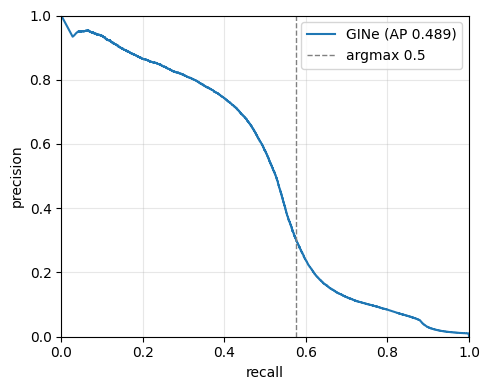

,threshold,alerts,TP,FP,precision,recall
budget,,,,,,
0.05%,0.9889,13405,10818,2587,0.8070,0.3139
0.10%,0.9101,26809,16618,10191,0.6199,0.4822
0.20%,0.6173,53617,19270,34347,0.3594,0.5592
0.50%,0.2677,134042,22190,111852,0.1655,0.6439
1.00%,0.1553,268083,26258,241825,0.0979,0.7620
2.00%,0.0272,536165,30003,506162,0.0560,0.8707
5.00%,0.0109,1340412,31466,1308946,0.0235,0.9131


In [48]:
# recall 별 precision — PR 곡선 (AP = 곡선 아래 면적) + recall 을 고정했을 때 정밀도와 알림 수
from sklearn.metrics import precision_recall_curve, average_precision_score
y_t = sc['y'].to_numpy(); s_t = sc['score'].to_numpy()
p, r, thr = precision_recall_curve(y_t, s_t)
fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(r, p, lw=1.5, label=f'GINe (AP {average_precision_score(y_t, s_t):.3f})')
ax.axvline(cb['matrix'].loc['argmax', 'recall'], ls='--', c='gray', lw=1, label='argmax 0.5')
ax.set_xlabel('recall'); ax.set_ylabel('precision'); ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUT_DIR / 'pr_curve.png', dpi=120); plt.show()

# 알림 예산별 — 상위 b% 를 알림으로 봤을 때 precision / recall
rows = []
for b in [0.0005, 0.001, 0.002, 0.005, 0.01, 0.02, 0.05]:
    t = np.quantile(s_t, 1 - b); hit = s_t >= t
    tp = int((hit & (y_t == 1)).sum()); alerts = int(hit.sum())
    rows.append(dict(budget=f'{b:.2%}', threshold=round(t, 4), alerts=alerts, TP=tp, FP=alerts - tp,
                     precision=round(tp / alerts, 4), recall=round(tp / n_pos, 4)))
bud_tab = pd.DataFrame(rows).set_index('budget'); bud_tab.to_csv(OUT_DIR / 'analysis_budget_table.csv'); bud_tab

## 9. 비교표 + 저장

In [41]:
pc_out = pc.assign(missed_rate=pc_rate['pred normal'].round(4)).sort_values('missed_rate', ascending=False)
pc_out.to_csv(OUT_DIR / 'analysis_confusion_pattern.csv'); pc_out

,pred normal,pred laundering,missed_rate
row_0,,,
NORMAL,26727107,46663,0.9983
UNMATCHED,13237,1036,0.9274
FAN-IN,255,1667,0.1327
BIPARTITE,180,1653,0.0982
GATHER-SCATTER,259,3526,0.0684
SCATTER-GATHER,253,3638,0.0650
STACK,210,3227,0.0611
RANDOM,56,1279,0.0419
CYCLE,66,1787,0.0356


In [43]:
compare_df = B.save_results(OUT_DIR, cfg, results, features=dict(tree=TREE_FEATURES, gnn=GNN_EDGE_FEATURES))
compare_df

AP      F1  F1_at_0.5  precision  recall  recall_at_1pct  \
model    split                                                                 
gine     val    0.5140  0.5605     0.4714     0.6867  0.4735          0.7562   
         test   0.4889  0.5452     0.3936     0.6595  0.4647          0.7620   
lightgbm val    0.3117  0.4681     0.2041     0.6445  0.3675          0.5741   
         test   0.3077  0.4700     0.1906     0.6875  0.3571          0.5852   
xgboost  val    0.3543  0.4900     0.4881     0.6475  0.3941          0.6222   
         test   0.3595  0.4915     0.4854     0.7059  0.3770          0.6452   

                unmatched_recall_at_1pct     ECE  train_sec  
model    split                                               
gine     val                      0.4403  0.0034      58202  
         test                     0.4692  0.0043      58202  
lightgbm val                      0.3742  0.0060         89  
         test                     0.3920  0.0058         89  
xgboost  val                      0.3519  0.0048        687  
         test                     0.3956  0.0044        687

In [44]:
# 01 전체 지표와 나란히
prev_c = pd.read_csv(Path.cwd() / 'results' / cfg.dataset / PREV_RUN / 'compare.csv', index_col=[0, 1])
pd.concat([prev_c.assign(run=PREV_RUN), compare_df.assign(run=RUN_NAME)]).reset_index().set_index(['run', 'model', 'split'])[['AP', 'F1', 'F1_at_0.5', 'recall_at_1pct', 'unmatched_recall_at_1pct']]

AP      F1  F1_at_0.5  \
run            model          split                              
basic_features lightgbm_basic val    0.0486  0.1230     0.1131   
                              test   0.0455  0.1166     0.1074   
               xgboost_basic  val    0.0561  0.1301     0.1272   
                              test   0.0511  0.1221     0.1187   
               gine_basic     val    0.4614  0.5182     0.4842   
                              test   0.3934  0.4716     0.4138   
               gine_eu_basic  val    0.4145  0.4550     0.4529   
                              test   0.2338  0.3375     0.3205   
pair_history   gine           val    0.5140  0.5605     0.4714   
                              test   0.4889  0.5452     0.3936   
               lightgbm       val    0.3117  0.4681     0.2041   
                              test   0.3077  0.4700     0.1906   
               xgboost        val    0.3543  0.4900     0.4881   
                              test   0.3595  0.4915     0.4854   

                                     recall_at_1pct  unmatched_recall_at_1pct  
run            model          split                                            
basic_features lightgbm_basic val            0.4389                    0.0696  
                              test           0.4412                    0.0789  
               xgboost_basic  val            0.4435                    0.0638  
                              test           0.4446                    0.0712  
               gine_basic     val            0.7447                    0.4265  
                              test           0.7447                    0.4324  
               gine_eu_basic  val            0.7208                    0.3860  
                              test           0.6695                    0.2955  
pair_history   gine           val            0.7562                    0.4403  
                              test           0.7620                    0.4692  
               lightgbm       val            0.5741                    0.3742  
                              test           0.5852                    0.3920  
               xgboost        val            0.6222                    0.3519  
                              test           0.6452                    0.3956

## 10. 다음
- 03: 계좌 단기 활동 (sender/receiver 1h·1일 거래 수·상대 수·금액 합) → FAN-IN/OUT, GATHER-SCATTER
- 04: 계좌 금액 분포 (1일 창 mean/std/max) → 스머핑, 허브 구별
- 05: GFP 모티프 (사이클·scatter-gather 참여 수) → CYCLE, SCATTER-GATHER